# Module 1 — Task 1: Exploratory analysis

**Brief (verbatim):**
> **Task 1: Exploratory analysis**
> Students should examine:
> - Investment distribution
> - ROI distribution
> - Risk categories
> - Business-unit performance
> - Relationship between growth and ROI
> - Relationship between investment and success

**How this notebook is laid out:**
- Setup, then data quality checks, then **one section per brief item**.
- Each section has a short explanation, then the commented code, then its table and chart.
- Every table and chart is also saved to `outputs/task1/`; the written findings (with the charts) are in `reports/task1_report.md`.

**Runs on its own or from `run_module_1.ipynb`.** It loads everything it needs itself.

**Shared code it uses** (also used by other tasks, so it lives in `helpers/`):
- `m01_data.py` loads and checks the CSV, and adds the derived columns;
- `m01_finance.py` computes cash flows and NPV (used inside `m01_data.py`).

**Units:** money in ₹ lakh (1 lakh = ₹1,00,000; 100 lakh = ₹1 crore). ROI and rates are in % a year.

## 0. Setup

Works locally and in Google Colab.
- **Locally:** open this notebook from `module_01_corporate_finance/notebooks/` and run all cells.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.

In [1]:
import sys
import json
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_01_corporate_finance"
OUT_DIR = MODULE_DIR / "outputs" / "task1"          # where tables and charts are saved
OUT_DIR.mkdir(parents=True, exist_ok=True)          # create it if missing

# Make the Module 1 helpers importable (helpers/m01_data.py, helpers/m01_finance.py).
sys.path.insert(0, str(MODULE_DIR / "helpers"))

# ---- Libraries -------------------------------------------------------------------------
import numpy as np                                               # maths on whole columns
import pandas as pd                                              # tables (DataFrames)
import matplotlib.pyplot as plt                                  # charts
from scipy import stats                                          # statistical tests
from statsmodels.stats.proportion import proportion_confint      # Wilson range for a success rate

# ---- Shared Module 1 code --------------------------------------------------------------
# load_initiatives_with_features(): reads data/strategic_initiatives.csv, checks it, and adds the
# derived columns (cash flows, 3-year NPV, revenue growth, cash return, ROI spread). It is shared
# because Task 2 needs the same columns (decision P-15).
from m01_data import load_initiatives_with_features

pd.set_option("display.width", 200, "display.max_columns", 20)   # show wide tables in full


def save(table: pd.DataFrame, fig, name: str, keep_index: bool = False) -> None:
    """Save one analysis: the table as CSV and the chart as PNG, both named after the step."""
    table.to_csv(OUT_DIR / f"{name}.csv", index=keep_index)
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Project folder found")
print("Outputs go to: ", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Project folder found
Outputs go to:  module_01_corporate_finance/outputs/task1


### Chart style
Set once and used by every chart:
- a light background, a quiet grid, no top or right border;
- three colours that stay distinguishable for colour-blind readers;
- each risk level always shown in the same colour.

The style lives in the helper `helpers/m01_style.py`, because Task 2 uses it too.

In [2]:
# Shared chart style (helpers/m01_style.py), so Task 1 and Task 2 charts look the same.
from m01_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, RISK_COLOURS
apply_style()

## 0b. Helpers and derived columns

- `success_rate_ci()` gives a success rate with its **95% Wilson range**: the range the true rate very likely lies in. This matters because some groups are small.
- `quality_checks()` lists the data cleaning checks.

The derived columns are added by the shared `load_initiatives_with_features()` in `helpers/m01_data.py`, because Task 2 needs them too. Nothing is invented:
  - cash flows (revenue − yearly operating cost);
  - 3-year NPV (Net Present Value: today's value of the cash flows minus the investment);
  - revenue growth from Year 1 to Year 3;
  - cash return (average yearly cash flow ÷ investment);
  - ROI spread (Expected_ROI − Interest_Rate, the hurdle gap).

**Formulas used here**
```text
Cash flow:      CFt = Revenue_Year t − Operating_Cost                       (t = 1, 2, 3; ₹ lakh)
3-year NPV:     NPV = −Initial_Investment + CF1/(1 + r) + CF2/(1 + r)² + CF3/(1 + r)³,   r = Interest_Rate ÷ 100
Revenue growth: (Revenue_Year3 ÷ Revenue_Year1 − 1) × 100                   (%)
Cash return:    average(CF1, CF2, CF3) ÷ Initial_Investment × 100           (% a year)
ROI spread:     Expected_ROI − Interest_Rate                                (% points)

Wilson 95% range for a success rate p̂ = successes ÷ n   (z = 1.96):
  centre     = (p̂ + z²/(2n)) ÷ (1 + z²/n)
  half-width = [z ÷ (1 + z²/n)] × √( p̂(1 − p̂)/n + z²/(4n²) )
  range      = centre ± half-width
```
Worked Wilson example (Low risk, 57 of 64, so p̂ = 0.891): centre = (0.891 + 3.84/128) ÷ (1 + 3.84/64) = 0.869; half-width = 0.077; range = 79% to 95%.

In [3]:
# =======================================================================================
# Helpers
# =======================================================================================
def success_rate_ci(successes: int, n: int) -> tuple[float, float, float]:
    """Success rate with its 95% Wilson range.

    Example: 57 successes out of 64 → rate 0.891, range 0.791 to 0.946.
    Why Wilson? The simple "rate ± 1.96 × standard error" range can go above 100% or
    below 0% for small groups or rates near 0/1; Wilson's formula does not.
    """
    # proportion_confint returns (lower, upper). alpha=0.05 means a 95% range.
    low, high = proportion_confint(successes, n, alpha=0.05, method="wilson")
    return successes / n, low, high


def quality_checks(df: pd.DataFrame) -> pd.DataFrame:
    """Data cleaning checks before any analysis. Returns a two-column table: Check | Result."""
    money = ["Initial_Investment", "Revenue_Year1", "Revenue_Year2", "Revenue_Year3", "Operating_Cost"]
    # Each line is one check. A boolean condition summed = how many rows meet it.
    checks = {
        "Rows": len(df),
        "Missing values (all columns)": int(df.isna().sum().sum()),
        "Duplicate Initiative_ID": int(df["Initiative_ID"].duplicated().sum()),
        "Negative money values": int((df[money] < 0).sum().sum()),
        "Expected_ROI ≤ 0": int((df["Expected_ROI"] <= 0).sum()),
        # Many rows sharing exactly the minimum value suggests a floor in how the data was made.
        "Expected_ROI exactly at the 2.00% floor": int((df["Expected_ROI"] == df["Expected_ROI"].min()).sum()),
        "Business_Growth < 0": int((df["Business_Growth"] < 0).sum()),
        "Revenue falls Year 1 → Year 3": int((df["Revenue_Year3"] < df["Revenue_Year1"]).sum()),
        # A first-year loss: yearly cost higher than first-year revenue.
        "Operating_Cost > Year 1 revenue": int((df["Operating_Cost"] > df["Revenue_Year1"]).sum()),
        # Listing the labels lets us spot spelling variants such as "Payment" vs "Payments".
        "Business_Unit labels": ", ".join(sorted(df["Business_Unit"].astype(str).unique())),
        "Risk_Rating labels": ", ".join(df["Risk_Rating"].cat.categories),
        "Historical_Success values": ", ".join(map(str, sorted(df["Historical_Success"].unique()))),
    }
    return pd.DataFrame({"Check": checks.keys(), "Result": checks.values()})

## 0c. Load the data and run the quality checks

**What we found:**
- Nothing is missing and there are no duplicate IDs.
- 11 initiatives sit exactly at a 2.00% Expected_ROI floor.
- 18 have a Year 1 operating cost above Year 1 revenue: a first-year loss, which is normal for a new project.
- One has negative Business_Growth.

All rows are kept (decision M1-10).

In [4]:
# Load once, add the derived columns once; every section below uses this same table `df`.
df = load_initiatives_with_features()
print(df.shape[0], "initiatives,", df.shape[1], "columns (given + derived)")

checks = quality_checks(df)
checks.to_csv(OUT_DIR / "0_quality_checks.csv", index=False)
display(checks)

180 initiatives, 21 columns (given + derived)


,Check,Result
0,Rows,180
1,Missing values (all columns),0
2,Duplicate Initiative_ID,0
3,Negative money values,0
4,Expected_ROI ≤ 0,0
5,Expected_ROI exactly at the 2.00% floor,11
6,Business_Growth < 0,1
7,Revenue falls Year 1 → Year 3,0
8,Operating_Cost > Year 1 revenue,18
9,Business_Unit labels,"Corporate Banking, Digital Banking, Payments, ..."


## 1. Investment distribution
How much money do initiatives ask for, and how does that differ by business unit?
- **Histogram:** how many initiatives fall in each ₹25-lakh band.
- **Box plot:** the box is the middle half of initiatives, the line is the median, the whiskers show the rest.

**Formulas used here**
```text
Mean   = Σ x ÷ n                       (the average)
Median = the middle value after sorting (half below, half above)
Q1, Q3 = values 25% and 75% of the way up the sorted list;  IQR = Q3 − Q1 (spread of the middle half)
₹ crore = ₹ lakh ÷ 100
```

,count,total_crore,mean,min,25%,50%,75%,max
All initiatives,180.0,283.4,157.5,31.5,89.3,155.3,226.9,296.5
Corporate Banking,35.0,62.3,178.1,42.2,104.2,190.0,248.4,296.5
Digital Banking,34.0,47.1,138.6,36.9,73.1,127.9,187.9,292.4
Payments,36.0,53.3,148.1,39.3,77.2,117.5,220.6,281.0
Risk Analytics,25.0,39.8,159.1,34.5,90.0,167.3,219.8,289.9
SME Lending,15.0,22.3,148.5,31.9,78.3,112.2,227.4,296.1
Wealth,35.0,58.6,167.5,31.5,116.4,163.7,226.7,291.9


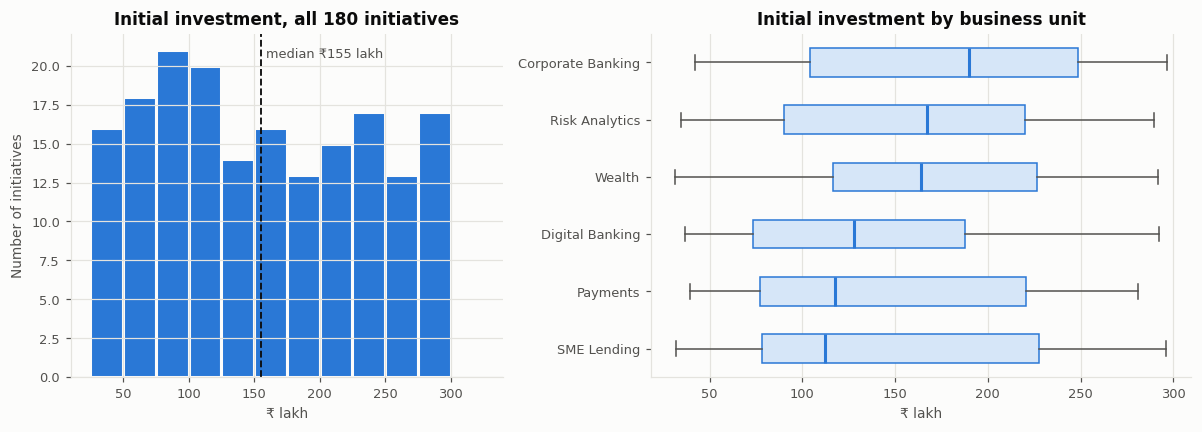

In [5]:
# =======================================================================================
# 1. Investment distribution
# =======================================================================================
def investment_distribution(df: pd.DataFrame):
    """Brief item: "Investment distribution".

    Table: count, total (₹ crore), mean, min, quartiles, max of Initial_Investment, overall and per unit.
    Chart: left = histogram (how many initiatives fall in each ₹25-lakh band);
           right = box plot per business unit (box = middle half, line = median, whiskers = spread).
    """
    inv = df["Initial_Investment"]

    # --- Table -----------------------------------------------------------------------
    # .describe() gives count, mean, std, min, 25%, 50% (median), 75%, max in one go.
    overall = inv.describe(percentiles=[0.25, 0.5, 0.75]).rename("All initiatives")
    # Same summary for each business unit; observed=True skips empty categories.
    by_unit = df.groupby("Business_Unit", observed=True)["Initial_Investment"].describe()[
        ["count", "mean", "min", "25%", "50%", "75%", "max"]]
    # Stack the "All" row on top of the per-unit rows. .to_frame().T turns a column into a row.
    table = pd.concat([overall.to_frame().T[by_unit.columns], by_unit]).round(1)
    # Insert a "total in ₹ crore" column (lakh ÷ 100) as the 2nd column.
    totals = df.groupby("Business_Unit", observed=True)["Initial_Investment"].sum() / 100
    table.insert(1, "total_crore", [inv.sum() / 100] + list(totals))
    table["total_crore"] = table["total_crore"].round(1)

    # --- Chart -----------------------------------------------------------------------
    # Two panels side by side; the right one a bit wider for the unit names.
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.25]})

    # Left: histogram with bins every ₹25 lakh from 25 to 325. A white edge separates bars.
    axes[0].hist(inv, bins=np.arange(25, 326, 25), color=BLUE, edgecolor=SURFACE, linewidth=2)
    # Dashed line at the median, with a small text label next to it.
    axes[0].axvline(inv.median(), color=INK, linewidth=1.2, linestyle="--")
    axes[0].text(inv.median() + 4, axes[0].get_ylim()[1] * 0.93, f"median ₹{inv.median():.0f} lakh",
                 color=INK_2, fontsize=8.5)
    axes[0].set(title="Initial investment, all 180 initiatives", xlabel="₹ lakh", ylabel="Number of initiatives")

    # Right: one horizontal box per unit, ordered by median so the chart reads bottom → top.
    order = by_unit["50%"].sort_values().index.tolist()
    data = [df.loc[df["Business_Unit"] == u, "Initial_Investment"] for u in order]
    axes[1].boxplot(data, vert=False, tick_labels=order, widths=0.5, patch_artist=True,
                    boxprops={"facecolor": "#d6e6f8", "edgecolor": BLUE},
                    medianprops={"color": BLUE, "linewidth": 2}, whiskerprops={"color": INK_2},
                    capprops={"color": INK_2}, flierprops={"markeredgecolor": INK_2})
    axes[1].set(title="Initial investment by business unit", xlabel="₹ lakh")
    axes[1].grid(axis="y", visible=False)      # horizontal grid lines would cut through boxes
    fig.tight_layout()                         # stop titles and labels overlapping
    return table, fig


# ---- Run it ----------------------------------------------------------------------------
table, fig = investment_distribution(df)                  # compute the numbers and draw the chart
save(table, fig, "1_investment_distribution", keep_index=True)   # write CSV + PNG to outputs/task1/
if table.attrs:                          # extra results (test p-values etc.) carried with the table
    print("Extra results:", table.attrs)
display(table)    # display() so the table also shows when run from run_module_1.ipynb

## 2. ROI distribution
ROI (Return on Investment) = promised yearly profit ÷ money invested, in % a year. We describe the given Expected_ROI.
- The **cash return** (average yearly cash flow ÷ investment) is a cross-check built from the revenue and cost columns.
- **Interest_Rate** is the yearly cost of money: the bar a project has to beat (the hurdle).

**Formulas used here**
```text
ROI (% a year)  = yearly profit ÷ money invested × 100
Cash return     = average(CF1, CF2, CF3) ÷ Initial_Investment × 100
Hurdle share    = count(Expected_ROI > Interest_Rate) ÷ number of initiatives
```

,Group,n,Expected_ROI_median,Expected_ROI_p25,Expected_ROI_p75,Cash_Return_median,Interest_Rate_median,Share_ROI_above_Interest
0,All initiatives,180,10.50,7.31,14.23,20.67,6.99,0.75
1,Unit: Corporate Banking,35,9.51,7.92,14.02,21.70,7.14,0.74
2,Unit: Digital Banking,34,12.60,9.20,15.39,20.99,6.93,0.82
3,Unit: Payments,36,10.24,7.60,14.03,21.14,6.98,0.81
4,Unit: Risk Analytics,25,10.41,5.21,12.67,20.37,7.08,0.64
5,Unit: SME Lending,15,11.38,5.78,13.14,15.71,7.04,0.67
6,Unit: Wealth,35,9.70,7.08,14.04,19.86,6.85,0.74
7,Risk: Low,64,11.99,8.11,14.59,21.01,6.87,0.80
8,Risk: Medium,72,11.35,8.00,14.47,20.95,6.98,0.78
9,Risk: High,44,8.32,5.62,11.52,19.90,7.26,0.64


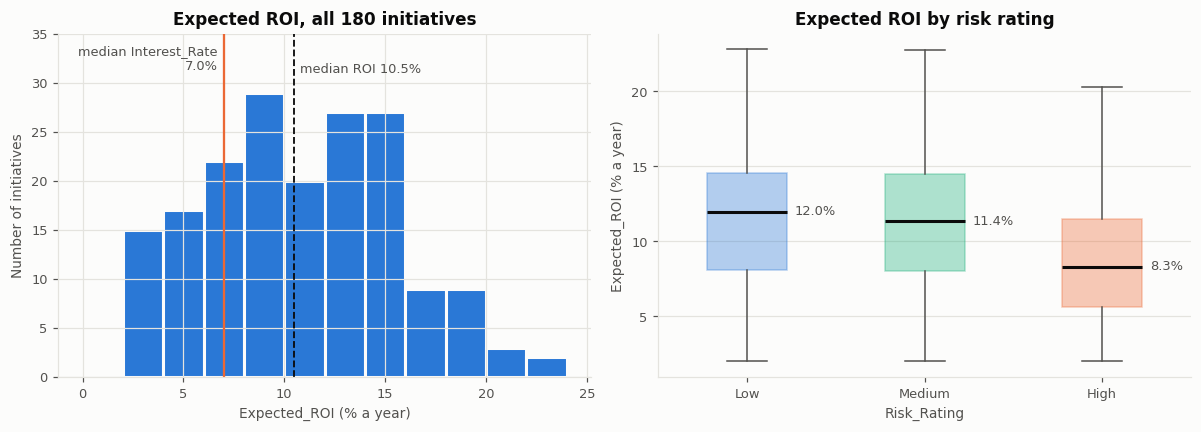

In [6]:
# =======================================================================================
# 2. ROI distribution
# =======================================================================================
def roi_distribution(df: pd.DataFrame):
    """Brief item: "ROI distribution".

    ROI (Return on Investment) = promised yearly profit ÷ money invested, in % a year.
    We describe the given Expected_ROI, and show the cash-based return (Cash_Return_Pct) as a
    cross-check, plus the share of initiatives whose ROI beats their Interest_Rate (hurdle).
    """
    # --- Table: one row per group (all, each unit, each risk level) --------------------
    # Build a list of (group name, sub-table) pairs, then summarise each the same way.
    groups = [("All initiatives", df)]
    groups += [(f"Unit: {u}", g) for u, g in df.groupby("Business_Unit", observed=True)]
    groups += [(f"Risk: {r}", g) for r, g in df.groupby("Risk_Rating", observed=True)]
    rows = []
    for name, grp in groups:
        rows.append({
            "Group": name,
            "n": len(grp),
            "Expected_ROI_median": grp["Expected_ROI"].median(),
            # 25th and 75th percentiles: the middle half of initiatives lies between them.
            "Expected_ROI_p25": grp["Expected_ROI"].quantile(0.25),
            "Expected_ROI_p75": grp["Expected_ROI"].quantile(0.75),
            "Cash_Return_median": grp["Cash_Return_Pct"].median(),
            "Interest_Rate_median": grp["Interest_Rate"].median(),
            # Mean of a True/False column = share of True (hurdle pass rate).
            "Share_ROI_above_Interest": (grp["Expected_ROI"] > grp["Interest_Rate"]).mean(),
        })
    table = pd.DataFrame(rows).round(2)

    # --- Chart -----------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    roi = df["Expected_ROI"]

    # Left: histogram in 2-point bands, with the median ROI (dashed) and the median
    # Interest_Rate (orange) so the reader sees how far ROI sits above the cost of money.
    axes[0].hist(roi, bins=np.arange(0, 25, 2), color=BLUE, edgecolor=SURFACE, linewidth=2)
    axes[0].axvline(roi.median(), color=INK, linewidth=1.2, linestyle="--")
    axes[0].axvline(df["Interest_Rate"].median(), color=ORANGE, linewidth=1.5)
    top = axes[0].get_ylim()[1]                      # current top of the y-axis
    axes[0].text(roi.median() + 0.3, top * 1.02, f"median ROI {roi.median():.1f}%", color=INK_2, fontsize=8.5)
    axes[0].text(df["Interest_Rate"].median() - 0.3, top * 1.02,
                 f"median Interest_Rate\n{df['Interest_Rate'].median():.1f}%",
                 color=INK_2, fontsize=8.5, ha="right", va="bottom")
    axes[0].set_ylim(0, top * 1.15)                  # head-room for the labels
    axes[0].set(title="Expected ROI, all 180 initiatives", xlabel="Expected_ROI (% a year)", ylabel="Number of initiatives")

    # Right: box plot of ROI per risk level, each in its risk colour, median printed beside it.
    levels = list(df["Risk_Rating"].cat.categories)  # Low, Medium, High
    data = [df.loc[df["Risk_Rating"] == r, "Expected_ROI"] for r in levels]
    bp = axes[1].boxplot(data, tick_labels=levels, widths=0.45, patch_artist=True,
                         medianprops={"color": INK, "linewidth": 2}, whiskerprops={"color": INK_2},
                         capprops={"color": INK_2}, flierprops={"markeredgecolor": INK_2})
    for patch, r in zip(bp["boxes"], levels):
        patch.set(facecolor=RISK_COLOURS[r], alpha=0.35, edgecolor=RISK_COLOURS[r])
    for i, d in enumerate(data, start=1):            # boxes sit at x = 1, 2, 3
        axes[1].text(i + 0.27, d.median(), f"{d.median():.1f}%", va="center", color=INK_2, fontsize=8.5)
    axes[1].set(title="Expected ROI by risk rating", xlabel="Risk_Rating", ylabel="Expected_ROI (% a year)")
    axes[1].grid(axis="x", visible=False)
    fig.tight_layout()
    return table, fig


# ---- Run it ----------------------------------------------------------------------------
table, fig = roi_distribution(df)                  # compute the numbers and draw the chart
save(table, fig, "2_roi_distribution", keep_index=False)   # write CSV + PNG to outputs/task1/
if table.attrs:                          # extra results (test p-values etc.) carried with the table
    print("Extra results:", table.attrs)
display(table)    # display() so the table also shows when run from run_module_1.ipynb

## 3. Risk categories
How many initiatives are Low, Medium and High risk, and does the success rate differ between them?
- Each success rate carries a 95% range.
- The **chi-square test** gives a p-value: below 0.05 means the difference is unlikely to be chance.

**Formulas used here**
```text
Success rate        = successes ÷ initiatives in the group   (with Wilson 95% range, see 0b)
Chi-square test:
  Expected count    = row total × column total ÷ grand total
  χ²                = Σ (Observed − Expected)² ÷ Expected      over every cell
  degrees of freedom = (rows − 1) × (columns − 1)
  p-value           = chance of a χ² this large if risk had no effect   (below 0.05 → unlikely to be chance)
```
Worked by hand on our table: if risk made no difference, the expected failures would be 64 × 42 ÷ 180 = 14.9 (Low), 16.8 (Medium) and 10.3 (High), against 7, 22 and 13 observed. Adding (Observed − Expected)² ÷ Expected over all six cells (failures and successes) gives χ² = 8.55 with (3 − 1) × (2 − 1) = 2 degrees of freedom, so p = 0.014. Most of it comes from Low risk failing far less often than expected (7 against 14.9).

Extra results: {'chi_square_p_value': 0.0139}


,Risk_Rating,n,share,success_rate,success_ci_low,success_ci_high,Expected_ROI_median,Investment_median,Total_investment_crore,NPV_3yr_median
0,Low,64,0.356,0.891,0.791,0.946,11.99,143.715,98.603,-55.548
1,Medium,72,0.400,0.694,0.580,0.789,11.35,166.080,119.423,-65.521
2,High,44,0.244,0.705,0.558,0.818,8.32,145.380,65.422,-50.351


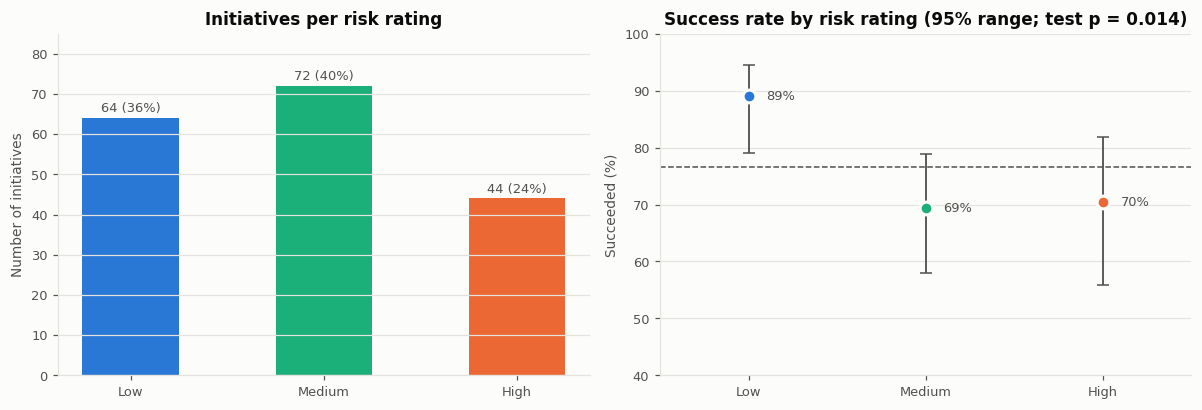

In [7]:
# =======================================================================================
# 3. Risk categories
# =======================================================================================
def risk_categories(df: pd.DataFrame):
    """Brief item: "Risk categories".

    For Low / Medium / High: count, share, success rate with 95% range, median ROI,
    median and total investment, median 3-year NPV. A chi-square test checks whether success
    rates really differ between risk levels (result stored in table.attrs).
    """
    rows = []
    for r, g in df.groupby("Risk_Rating", observed=True):
        # Successes = sum of the 0/1 column; n = group size.
        rate, lo, hi = success_rate_ci(int(g["Historical_Success"].sum()), len(g))
        rows.append({"Risk_Rating": r, "n": len(g), "share": len(g) / len(df),
                     "success_rate": rate, "success_ci_low": lo, "success_ci_high": hi,
                     "Expected_ROI_median": g["Expected_ROI"].median(),
                     "Investment_median": g["Initial_Investment"].median(),
                     "Total_investment_crore": g["Initial_Investment"].sum() / 100,
                     "NPV_3yr_median": g["NPV_3yr"].median()})
    table = pd.DataFrame(rows).round(3)

    # Chi-square test of independence on the 3 × 2 table (risk level × failed/succeeded).
    # It compares the observed counts with the counts we would expect if risk had no effect.
    # p = probability of seeing differences this big by chance alone; below 0.05 → real difference.
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(df["Risk_Rating"], df["Historical_Success"]))
    table.attrs["chi_square_p_value"] = round(float(p), 4)    # .attrs = extra info carried by the table

    # --- Chart -----------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    x = np.arange(len(table))                                  # positions 0, 1, 2

    # Left: bar per risk level with "count (share)" printed above each bar.
    axes[0].bar(x, table["n"], width=0.5, color=[RISK_COLOURS[r] for r in table["Risk_Rating"]])
    for i, n in enumerate(table["n"]):
        axes[0].text(i, n + 1.5, f"{n} ({n / len(df):.0%})", ha="center", color=INK_2, fontsize=8.5)
    axes[0].set(xticks=x, xticklabels=table["Risk_Rating"], title="Initiatives per risk rating",
                ylabel="Number of initiatives", ylim=(0, table["n"].max() * 1.18))
    axes[0].grid(axis="x", visible=False)

    # Right: success rate as a dot, with an error bar showing the 95% range.
    # errorbar needs the distance below and above the dot, not the end points.
    axes[1].errorbar(x, table["success_rate"] * 100,
                     yerr=[(table["success_rate"] - table["success_ci_low"]) * 100,
                           (table["success_ci_high"] - table["success_rate"]) * 100],
                     fmt="none", ecolor=INK_2, elinewidth=1.2, capsize=4)
    for i, r in enumerate(table["Risk_Rating"]):
        axes[1].scatter(i, table["success_rate"].iloc[i] * 100, s=70, color=RISK_COLOURS[r],
                        edgecolor=SURFACE, linewidth=2, zorder=3)     # zorder=3 draws dots on top
        axes[1].text(i + 0.1, table["success_rate"].iloc[i] * 100, f"{table['success_rate'].iloc[i]:.0%}",
                     va="center", color=INK_2, fontsize=8.5)
    # Dashed line = overall success rate (77%) for reference.
    axes[1].axhline(df["Historical_Success"].mean() * 100, color=INK_2, linestyle="--", linewidth=1)
    axes[1].set(xticks=x, xticklabels=table["Risk_Rating"], ylim=(40, 100), xlim=(-0.5, len(x) - 0.5),
                title=f"Success rate by risk rating (95% range; test p = {p:.3f})", ylabel="Succeeded (%)")
    axes[1].grid(axis="x", visible=False)
    fig.tight_layout()
    return table, fig


# ---- Run it ----------------------------------------------------------------------------
table, fig = risk_categories(df)                  # compute the numbers and draw the chart
save(table, fig, "3_risk_categories", keep_index=False)   # write CSV + PNG to outputs/task1/
if table.attrs:                          # extra results (test p-values etc.) carried with the table
    print("Extra results:", table.attrs)
display(table)    # display() so the table also shows when run from run_module_1.ipynb

## 4. Business-unit performance
For each unit: success rate, promised ROI, and 3-year NPV.
- NPV (Net Present Value) = today's value of the 3 years of cash flow minus the investment, discounted at each row's Interest_Rate (decisions M1-02, M1-03).
- NPV is shown in its own panel, not on a second axis, because it is in ₹ while ROI is in %.

**Formulas used here**
```text
3-year NPV = −Initial_Investment + CF1/(1 + r) + CF2/(1 + r)² + CF3/(1 + r)³,   r = Interest_Rate ÷ 100
Success rate with Wilson range and chi-square test: as in sections 0b and 3
```
Example (initiative 1002): −286.69 + 22.51/1.0663 + 52.53/1.0663² + 60.04/1.0663³ ≈ −169.9 ₹ lakh.

Extra results: {'chi_square_p_value': 0.3586}


,Business_Unit,n,Total_investment_crore,success_rate,success_ci_low,success_ci_high,Expected_ROI_median,Cash_Return_median,Business_Growth_median,NPV_3yr_median,NPV_3yr_positive,High_risk_share
4,SME Lending,15,22.279,0.867,0.621,0.963,11.380,15.706,7.380,-54.185,1,0.133
3,Risk Analytics,25,39.772,0.840,0.653,0.936,10.410,20.370,8.030,-77.117,0,0.240
1,Digital Banking,34,47.138,0.794,0.632,0.897,12.595,20.989,9.360,-56.300,1,0.265
2,Payments,36,53.325,0.778,0.619,0.883,10.245,21.137,8.595,-62.348,0,0.306
5,Wealth,35,58.613,0.771,0.610,0.879,9.700,19.858,7.820,-47.092,4,0.286
0,Corporate Banking,35,62.321,0.629,0.463,0.768,9.510,21.701,8.350,-69.941,2,0.171


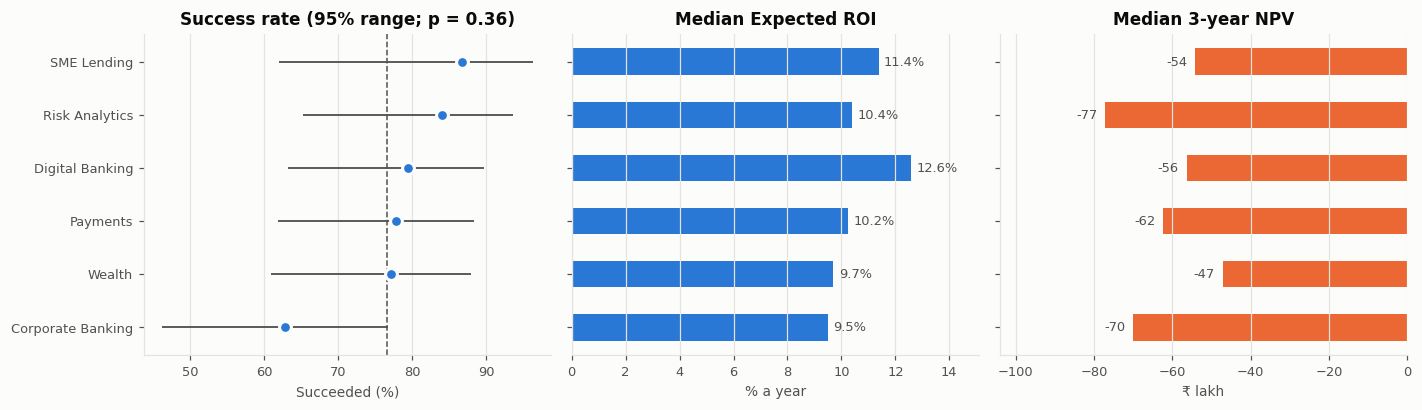

In [8]:
# =======================================================================================
# 4. Business-unit performance
# =======================================================================================
def business_unit_performance(df: pd.DataFrame):
    """Brief item: "Business-unit performance".

    Per unit: count, total investment, success rate with 95% range, median Expected ROI,
    median cash return, median Business_Growth, median 3-year NPV, how many have NPV > 0,
    and the share of High-risk initiatives. Chi-square test across units.
    """
    rows = []
    for u, g in df.groupby("Business_Unit", observed=True):
        rate, lo, hi = success_rate_ci(int(g["Historical_Success"].sum()), len(g))
        rows.append({"Business_Unit": u, "n": len(g),
                     "Total_investment_crore": g["Initial_Investment"].sum() / 100,
                     "success_rate": rate, "success_ci_low": lo, "success_ci_high": hi,
                     "Expected_ROI_median": g["Expected_ROI"].median(),
                     "Cash_Return_median": g["Cash_Return_Pct"].median(),
                     "Business_Growth_median": g["Business_Growth"].median(),
                     "NPV_3yr_median": g["NPV_3yr"].median(),
                     "NPV_3yr_positive": int((g["NPV_3yr"] > 0).sum()),
                     "High_risk_share": (g["Risk_Rating"] == "High").mean()})
    # Sort best success rate first for the table.
    table = pd.DataFrame(rows).sort_values("success_rate", ascending=False).round(3)
    # Same chi-square idea as for risk: 6 units × failed/succeeded.
    _, p, _, _ = stats.chi2_contingency(pd.crosstab(df["Business_Unit"], df["Historical_Success"]))
    table.attrs["chi_square_p_value"] = round(float(p), 4)

    # --- Chart: three panels sharing the unit names on the left -------------------------
    t = table.sort_values("success_rate")      # lowest at the bottom
    y = np.arange(len(t))
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)

    # Panel 1: success rate dot + horizontal line for the 95% range; dashed = overall rate.
    axes[0].hlines(y, t["success_ci_low"] * 100, t["success_ci_high"] * 100, color=INK_2, linewidth=1.2)
    axes[0].scatter(t["success_rate"] * 100, y, s=60, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
    axes[0].axvline(df["Historical_Success"].mean() * 100, color=INK_2, linestyle="--", linewidth=1)
    axes[0].set(yticks=y, yticklabels=t["Business_Unit"], xlabel="Succeeded (%)",
                title=f"Success rate (95% range; p = {p:.2f})")

    # Panel 2: median Expected ROI per unit, value printed at the end of each bar.
    axes[1].barh(y, t["Expected_ROI_median"], height=0.5, color=BLUE)
    for i, v in enumerate(t["Expected_ROI_median"]):
        axes[1].text(v + 0.2, i, f"{v:.1f}%", va="center", color=INK_2, fontsize=8.5)
    axes[1].set(xlabel="% a year", title="Median Expected ROI", xlim=(0, t["Expected_ROI_median"].max() * 1.2))

    # Panel 3: median 3-year NPV (negative, so bars go left from 0).
    # A separate panel, not a second axis, because NPV (₹ lakh) and ROI (%) have different units.
    axes[2].barh(y, t["NPV_3yr_median"], height=0.5, color=ORANGE)
    for i, v in enumerate(t["NPV_3yr_median"]):
        axes[2].text(v - 2, i, f"{v:.0f}", va="center", ha="right", color=INK_2, fontsize=8.5)
    axes[2].set(xlabel="₹ lakh", title="Median 3-year NPV", xlim=(t["NPV_3yr_median"].min() * 1.35, 0))
    for ax in axes:
        ax.grid(axis="y", visible=False)
    fig.tight_layout()
    return table, fig


# ---- Run it ----------------------------------------------------------------------------
table, fig = business_unit_performance(df)                  # compute the numbers and draw the chart
save(table, fig, "4_business_unit_performance", keep_index=False)   # write CSV + PNG to outputs/task1/
if table.attrs:                          # extra results (test p-values etc.) carried with the table
    print("Extra results:", table.attrs)
display(table)    # display() so the table also shows when run from run_module_1.ipynb

## 5. Relationship between growth and ROI
The brief does not say which "growth" it means, so we test three (decision M1-09):
- **Business_Growth:** how fast the unit grows;
- **GDP_Growth:** how fast the economy grows;
- **Revenue growth:** the project's own revenue from Year 1 to Year 3.

r is the correlation, from −1 to +1; 0 means no straight-line link.

**Formulas used here**
```text
Pearson r   = Σ (x − x̄)(y − ȳ) ÷ √[ Σ (x − x̄)² × Σ (y − ȳ)² ]        (−1 to +1; x̄, ȳ = means)
Spearman ρ  = Pearson r computed on the ranks of x and y               (robust to outliers and curves)
Straight-line fit  y = a + b × x:   b = r × SD(y) ÷ SD(x),   a = ȳ − b × x̄
```
Example: r = 0.56, SD(ROI) = 4.83, SD(Business_Growth) = 2.97 → b = 0.56 × 4.83 ÷ 2.97 ≈ 0.91 ROI points per growth point.

,Growth_measure,ROI_measure,Pearson_r,Pearson_p,Spearman_rho,Spearman_p,Slope_ROI_per_1pt_growth
0,Business_Growth,Expected_ROI,0.5606,0.0000,0.5558,0.0000,0.9122
1,Business_Growth,Cash_Return_Pct,0.3278,0.0000,0.3262,0.0000,1.2362
2,GDP_Growth,Expected_ROI,0.1179,0.1150,0.1225,0.1014,0.3335
3,GDP_Growth,Cash_Return_Pct,0.0624,0.4051,0.0354,0.6371,0.4092
4,Revenue_Growth_Y1_Y3,Expected_ROI,0.0345,0.6458,0.0508,0.4986,0.0123
5,Revenue_Growth_Y1_Y3,Cash_Return_Pct,0.2209,0.0029,0.1936,0.0092,0.1824


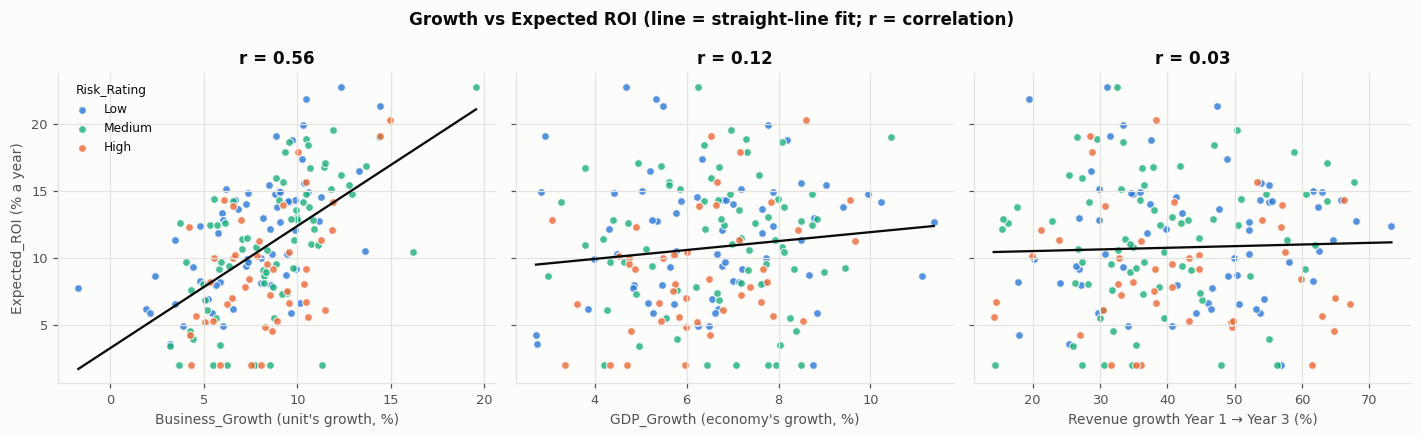

In [9]:
# =======================================================================================
# 5. Relationship between growth and ROI
# =======================================================================================
# The brief does not say which "growth", so we test three (decision M1-09).
GROWTH_MEASURES = {
    "Business_Growth": "Business_Growth (unit's growth, %)",
    "GDP_Growth": "GDP_Growth (economy's growth, %)",
    "Revenue_Growth_Y1_Y3": "Revenue growth Year 1 → Year 3 (%)",
}


def growth_vs_roi(df: pd.DataFrame):
    """Brief item: "Relationship between growth and ROI".

    For each growth measure × each ROI measure (Expected_ROI and Cash_Return_Pct):
      Pearson r   = strength of the straight-line link (−1 to +1),
      Spearman ρ  = same but on ranks (robust to outliers and curves),
      p-values    = chance of a link this strong if there were really none,
      slope       = how many ROI points come with +1 point of growth (straight-line fit).
    Chart: one scatter per growth measure, points coloured by risk, with the fitted line.
    """
    rows = []
    for col in GROWTH_MEASURES:
        for roi_col in ["Expected_ROI", "Cash_Return_Pct"]:
            pr, pp = stats.pearsonr(df[col], df[roi_col])        # Pearson correlation and p-value
            sr, sp = stats.spearmanr(df[col], df[roi_col])       # Spearman correlation and p-value
            # np.polyfit(x, y, 1) fits y = slope × x + intercept and returns [slope, intercept].
            slope = np.polyfit(df[col], df[roi_col], 1)[0]
            rows.append({"Growth_measure": col, "ROI_measure": roi_col, "Pearson_r": pr, "Pearson_p": pp,
                         "Spearman_rho": sr, "Spearman_p": sp, "Slope_ROI_per_1pt_growth": slope})
    table = pd.DataFrame(rows).round(4)

    # --- Chart -----------------------------------------------------------------------
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
    for ax, (col, label) in zip(axes, GROWTH_MEASURES.items()):
        # One scatter call per risk level so each gets its colour and a legend entry.
        for r in df["Risk_Rating"].cat.categories:
            g = df[df["Risk_Rating"] == r]
            ax.scatter(g[col], g["Expected_ROI"], s=26, color=RISK_COLOURS[r], alpha=0.8,
                       edgecolor=SURFACE, linewidth=0.8, label=r)
        # Straight-line fit across all points: ROI = a + b × growth.
        b, a = np.polyfit(df[col], df["Expected_ROI"], 1)
        xs = np.linspace(df[col].min(), df[col].max(), 50)     # 50 evenly spaced x values for the line
        ax.plot(xs, a + b * xs, color=INK, linewidth=1.5)
        # Look up the Pearson r we computed above for the panel title.
        r_val = table.query("Growth_measure == @col and ROI_measure == 'Expected_ROI'")["Pearson_r"].iloc[0]
        ax.set(xlabel=label, title=f"r = {r_val:.2f}")
    axes[0].set_ylabel("Expected_ROI (% a year)")
    axes[0].legend(title="Risk_Rating", frameon=False, fontsize=8, title_fontsize=8, loc="upper left")
    fig.suptitle("Growth vs Expected ROI (line = straight-line fit; r = correlation)", fontsize=11, fontweight="bold")
    fig.tight_layout()
    return table, fig


# ---- Run it ----------------------------------------------------------------------------
table, fig = growth_vs_roi(df)                  # compute the numbers and draw the chart
save(table, fig, "5_growth_vs_roi", keep_index=False)   # write CSV + PNG to outputs/task1/
if table.attrs:                          # extra results (test p-values etc.) carried with the table
    print("Extra results:", table.attrs)
display(table)    # display() so the table also shows when run from run_module_1.ipynb

## 6. Relationship between investment and success
Do bigger projects succeed more or less often?
- Investments are split into equal thirds of 60 each (decision M1-12), and each third gets a success rate with its 95% range.
- The **Mann–Whitney test** compares the investment sizes of successful and failed initiatives.

**Formulas used here**
```text
Thirds (terciles): sort by Initial_Investment and cut into 3 groups of 60
Mann–Whitney U = R1 − n1(n1 + 1) ÷ 2      (R1 = sum of ranks of group 1, n1 = its size)
  U ÷ (n1 × n2) = share of (success, failure) pairs where the success has the larger investment
Point-biserial r = Pearson r between the 0/1 success column and Initial_Investment
```
Our result: U ÷ (138 × 42) = 2,937 ÷ 5,796 = 0.51 (a coin toss); p = 0.90.

Extra results: {'median_succeeded': 151.0, 'median_failed': 162.4, 'mann_whitney_p': 0.896, 'point_biserial_r': 0.01}


,Investment_band,n,range_lakh,success_rate,success_ci_low,success_ci_high,NPV_3yr_median
0,Small,60,31–108,0.767,0.646,0.856,-24.747
1,Mid-size,60,109–201,0.783,0.664,0.869,-65.837
2,Large,60,201–296,0.750,0.628,0.842,-123.552


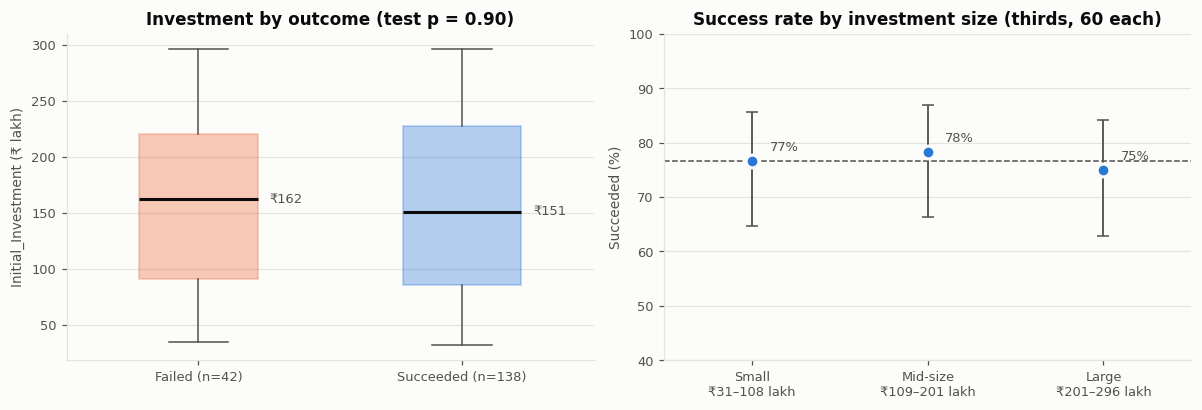

In [10]:
# =======================================================================================
# 6. Relationship between investment and success
# =======================================================================================
def investment_vs_success(df: pd.DataFrame):
    """Brief item: "Relationship between investment and success".

    - Split initiatives into three equal-size investment bands (decision M1-12) and compare
      success rates with 95% ranges.
    - Compare investment of successes vs failures: medians + Mann-Whitney test.
    - Point-biserial correlation (Pearson r between a 0/1 column and a number).
    """
    out = df.copy()
    # pd.qcut splits by quantiles: 3 bands with 60 initiatives each.
    out["Investment_band"] = pd.qcut(out["Initial_Investment"], 3, labels=["Small", "Mid-size", "Large"])
    rows = []
    for band, g in out.groupby("Investment_band", observed=True):
        rate, lo, hi = success_rate_ci(int(g["Historical_Success"].sum()), len(g))
        rows.append({"Investment_band": band, "n": len(g),
                     "range_lakh": f"{g['Initial_Investment'].min():.0f}–{g['Initial_Investment'].max():.0f}",
                     "success_rate": rate, "success_ci_low": lo, "success_ci_high": hi,
                     "NPV_3yr_median": g["NPV_3yr"].median()})
    table = pd.DataFrame(rows).round(3)

    # Investments of successful vs failed initiatives.
    succ = out.loc[out["Historical_Success"] == 1, "Initial_Investment"]
    fail = out.loc[out["Historical_Success"] == 0, "Initial_Investment"]
    # Mann-Whitney: ranks all 180 investments and asks whether one group's ranks are
    # systematically higher. No bell-curve assumption. Large p → no evidence of a difference.
    mw = stats.mannwhitneyu(succ, fail)
    # Point-biserial r: correlation between success (0/1) and investment size.
    pb = stats.pointbiserialr(out["Historical_Success"], out["Initial_Investment"])
    table.attrs.update({"median_succeeded": round(float(succ.median()), 1),
                        "median_failed": round(float(fail.median()), 1),
                        "mann_whitney_p": round(float(mw.pvalue), 3),
                        "point_biserial_r": round(float(pb.statistic), 3)})

    # --- Chart -----------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

    # Left: box plot of investment for failed (orange) vs succeeded (blue).
    data = [fail, succ]
    bp = axes[0].boxplot(data, tick_labels=[f"Failed (n={len(fail)})", f"Succeeded (n={len(succ)})"],
                         widths=0.45, patch_artist=True, medianprops={"color": INK, "linewidth": 2},
                         whiskerprops={"color": INK_2}, capprops={"color": INK_2})
    for patch, c in zip(bp["boxes"], [ORANGE, BLUE]):
        patch.set(facecolor=c, alpha=0.35, edgecolor=c)
    for i, d in enumerate(data, start=1):
        axes[0].text(i + 0.27, d.median(), f"₹{d.median():.0f}", va="center", color=INK_2, fontsize=8.5)
    axes[0].set(ylabel="Initial_Investment (₹ lakh)", title=f"Investment by outcome (test p = {mw.pvalue:.2f})")
    axes[0].grid(axis="x", visible=False)

    # Right: success rate per band with 95% range (same style as the risk chart).
    x = np.arange(len(table))
    axes[1].errorbar(x, table["success_rate"] * 100,
                     yerr=[(table["success_rate"] - table["success_ci_low"]) * 100,
                           (table["success_ci_high"] - table["success_rate"]) * 100],
                     fmt="none", ecolor=INK_2, elinewidth=1.2, capsize=4)
    axes[1].scatter(x, table["success_rate"] * 100, s=70, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
    for i, v in enumerate(table["success_rate"]):
        # Label sits slightly above the dot so it does not collide with the dashed line.
        axes[1].text(i + 0.1, v * 100 + 2.5, f"{v:.0%}", va="center", color=INK_2, fontsize=8.5)
    axes[1].set(xticks=x, xticklabels=[f"{b}\n₹{r} lakh" for b, r in zip(table["Investment_band"], table["range_lakh"])],
                ylim=(40, 100), xlim=(-0.5, 2.5), ylabel="Succeeded (%)",
                title="Success rate by investment size (thirds, 60 each)")
    axes[1].axhline(df["Historical_Success"].mean() * 100, color=INK_2, linestyle="--", linewidth=1)
    axes[1].grid(axis="x", visible=False)
    fig.tight_layout()
    return table, fig


# ---- Run it ----------------------------------------------------------------------------
table, fig = investment_vs_success(df)                  # compute the numbers and draw the chart
save(table, fig, "6_investment_vs_success", keep_index=False)   # write CSV + PNG to outputs/task1/
if table.attrs:                          # extra results (test p-values etc.) carried with the table
    print("Extra results:", table.attrs)
display(table)    # display() so the table also shows when run from run_module_1.ipynb

## 7. Supporting view: correlations
The correlation of every numeric column with success, with Expected_ROI and with 3-year NPV, in one table.

```text
Each cell = Pearson r between the row's column and Historical_Success / Expected_ROI / NPV_3yr
```

In [11]:
# =======================================================================================
# Supporting view
# =======================================================================================
def correlation_table(df: pd.DataFrame) -> pd.DataFrame:
    """Correlation of every numeric input with success, Expected ROI and 3-year NPV.

    Helps answer "what moves with what" in one table. Correlation of a column with the
    0/1 success column is the point-biserial r.
    """
    cols = ["Initial_Investment", "Revenue_Year1", "Revenue_Year3", "Operating_Cost", "Expected_ROI",
            "Business_Growth", "GDP_Growth", "Interest_Rate", "Competition_Index",
            "Revenue_Growth_Y1_Y3", "Cash_Return_Pct", "ROI_Spread", "NPV_3yr"]
    # .corr() computes Pearson r for every pair of columns; we keep three target columns.
    corr = df[cols + ["Historical_Success"]].corr()
    return corr.loc[cols, ["Historical_Success", "Expected_ROI", "NPV_3yr"]].round(2)


corr = correlation_table(df)
corr.to_csv(OUT_DIR / "7_correlations.csv")
display(corr)

,Historical_Success,Expected_ROI,NPV_3yr
Initial_Investment,0.01,0.07,-0.60
Revenue_Year1,0.01,0.32,-0.33
Revenue_Year3,0.03,0.32,-0.31
Operating_Cost,0.03,0.07,-0.80
Expected_ROI,0.12,1.00,0.35
Business_Growth,0.09,0.56,0.23
GDP_Growth,-0.03,0.12,0.03
Interest_Rate,-0.02,-0.19,-0.08
Competition_Index,-0.07,0.01,-0.03
Revenue_Growth_Y1_Y3,0.07,0.03,0.15


## 8. Key numbers
The headline figures quoted in `reports/task1_report.md`. They are saved so the report can be checked against the code.

In [12]:
key = {
    "rows": len(df),
    "success_rate": round(float(df["Historical_Success"].mean()), 3),
    "total_investment_crore": round(float(df["Initial_Investment"].sum() / 100), 1),   # lakh ÷ 100 = crore
    "risk_chi_square_p": risk_categories(df)[0].attrs["chi_square_p_value"],
    "unit_chi_square_p": business_unit_performance(df)[0].attrs["chi_square_p_value"],
    "investment_vs_success": investment_vs_success(df)[0].attrs,
    "npv_3yr_positive": int((df["NPV_3yr"] > 0).sum()),        # initiatives with positive 3-year NPV
    "hurdle_pass": int((df["ROI_Spread"] > 0).sum()),          # Expected_ROI above Interest_Rate
}
plt.close("all")   # the three calls above redraw charts; close them so they are not shown twice
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=2, default=float), encoding="utf-8")
print(json.dumps(key, indent=2, default=float))

{
  "rows": 180,
  "success_rate": 0.767,
  "total_investment_crore": 283.4,
  "risk_chi_square_p": 0.0139,
  "unit_chi_square_p": 0.3586,
  "investment_vs_success": {
    "median_succeeded": 151.0,
    "median_failed": 162.4,
    "mann_whitney_p": 0.896,
    "point_biserial_r": 0.01
  },
  "npv_3yr_positive": 8,
  "hurdle_pass": 135
}


## 9. Board view in ₹: where the capital sits and where it was lost

Steps 1–7 answered the brief item by item. A Board reads the same data in **money**: where is our capital, and where did we lose it?

**Terms:**
- **Capital** = Initial_Investment (₹ lakh; ÷ 100 for ₹ crore).
- **Failed capital** = the Initial_Investment of initiatives that failed (Historical_Success = 0). That is money committed to projects that did not deliver.
- **Passes hurdle** = Expected_ROI above Interest_Rate, i.e. the promised yearly return beats the yearly cost of money.

```text
Share of capital           = capital of the group ÷ capital of all 180 initiatives
Failed share of its capital = failed capital of the group ÷ capital of the group
Share of all failed capital = failed capital of the group ÷ failed capital of all 180 initiatives
```

If a group's share of failed capital is much bigger than its share of capital, the group loses money out of proportion to its size. That's where the Board should look first.

Total capital ₹283.4 crore; failed capital ₹65.5 crore (23% of all capital)


,Initiatives,Capital (₹ crore),Share of capital,Success rate,Failed capital (₹ crore),Failed share of its capital,Share of all failed capital,Median Expected_ROI (%),Passes hurdle
Risk_Rating,,,,,,,,,
Low,64,98.603,0.348,0.891,9.190,0.093,0.14,11.99,0.797
Medium,72,119.423,0.421,0.694,35.348,0.296,0.54,11.35,0.778
High,44,65.422,0.231,0.705,20.978,0.321,0.32,8.32,0.636


,Initiatives,Capital (₹ crore),Share of capital,Success rate,Failed capital (₹ crore),Failed share of its capital,Share of all failed capital,Median Expected_ROI (%),Passes hurdle
Business_Unit,,,,,,,,,
Corporate Banking,35,62.321,0.220,0.629,23.096,0.371,0.353,9.510,0.743
Wealth,35,58.613,0.207,0.771,12.279,0.209,0.187,9.700,0.743
Payments,36,53.325,0.188,0.778,11.961,0.224,0.183,10.245,0.806
Digital Banking,34,47.138,0.166,0.794,7.815,0.166,0.119,12.595,0.824
SME Lending,15,22.279,0.079,0.867,5.249,0.236,0.080,11.380,0.667
Risk Analytics,25,39.772,0.140,0.840,5.116,0.129,0.078,10.410,0.640


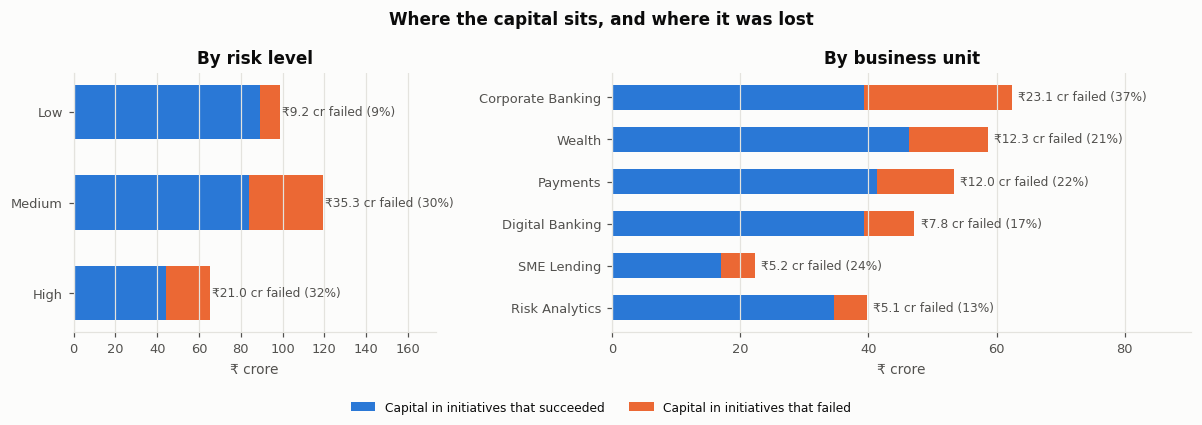

In [13]:
# ---- 9. Board view in ₹: capital, success and failed capital by risk level and by business unit ----
FAILED_TOTAL = df.loc[df["Historical_Success"] == 0, "Initial_Investment"].sum()   # ₹ lakh lost to failures
CAPITAL_TOTAL = df["Initial_Investment"].sum()                                   # ₹ lakh committed in total


def board_view(group_col: str) -> pd.DataFrame:
    """One row per group (risk level or business unit) with the money view of Task 1.

    For each group:
      capital and its share of all capital, success rate, failed capital (₹ crore), the share of
      its own capital that failed, its share of ALL failed capital, median Expected_ROI, and the
      share of its initiatives whose Expected_ROI beats their Interest_Rate (passes the hurdle)."""
    failed_inv = df["Initial_Investment"].where(df["Historical_Success"] == 0, 0)   # investment if failed, else 0
    table = (df.assign(Failed_investment=failed_inv, Passes_hurdle=df["ROI_Spread"] > 0)
               .groupby(group_col, observed=True)
               .agg(Initiatives=("Initial_Investment", "size"),
                    Capital=("Initial_Investment", "sum"),
                    Success_rate=("Historical_Success", "mean"),
                    Failed=("Failed_investment", "sum"),
                    Median_Expected_ROI=("Expected_ROI", "median"),
                    Passes_hurdle=("Passes_hurdle", "mean")))
    out = pd.DataFrame({
        "Initiatives": table["Initiatives"],
        "Capital (₹ crore)": table["Capital"] / 100,
        "Share of capital": table["Capital"] / CAPITAL_TOTAL,
        "Success rate": table["Success_rate"],
        "Failed capital (₹ crore)": table["Failed"] / 100,
        "Failed share of its capital": table["Failed"] / table["Capital"],
        "Share of all failed capital": table["Failed"] / FAILED_TOTAL,
        "Median Expected_ROI (%)": table["Median_Expected_ROI"],
        "Passes hurdle": table["Passes_hurdle"],
    })
    return out.round(3)


board_risk = board_view("Risk_Rating")
board_unit = board_view("Business_Unit").sort_values("Share of all failed capital", ascending=False)
board_risk.reset_index().to_csv(OUT_DIR / "9_board_view_risk.csv", index=False)
board_unit.reset_index().to_csv(OUT_DIR / "FINAL_M1_T1_business_unit_view.csv", index=False)
print(f"Total capital ₹{CAPITAL_TOTAL / 100:.1f} crore; failed capital ₹{FAILED_TOTAL / 100:.1f} crore "
      f"({FAILED_TOTAL / CAPITAL_TOTAL:.0%} of all capital)")
display(board_risk)
display(board_unit)

# Chart: capital by risk level and by unit, split into capital that succeeded and capital that failed.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
for ax, table, title in [(axes[0], board_risk, "By risk level"), (axes[1], board_unit, "By business unit")]:
    names = [str(i) for i in table.index][::-1]                       # first row at the top
    failed_cr = table["Failed capital (₹ crore)"].to_numpy()[::-1]
    ok_cr = table["Capital (₹ crore)"].to_numpy()[::-1] - failed_cr
    ax.barh(names, ok_cr, color=BLUE, height=0.6, label="Capital in initiatives that succeeded")
    ax.barh(names, failed_cr, left=ok_cr, color=ORANGE, height=0.6, label="Capital in initiatives that failed")
    for i, (ok, bad) in enumerate(zip(ok_cr, failed_cr)):
        ax.text(ok + bad + 1, i, f"₹{bad:.1f} cr failed ({bad / (ok + bad):.0%})", va="center", color=INK_2, fontsize=8)
    ax.set(title=title, xlabel="₹ crore", xlim=(0, max(ok_cr + failed_cr) * 1.45))
    ax.grid(axis="y", visible=False)
# One legend for both panels, below the charts, so it never covers a bar or label.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=8, frameon=False)
fig.suptitle("Where the capital sits, and where it was lost", fontsize=11, fontweight="bold")
fig.tight_layout(rect=(0, 0.07, 1, 1))              # leave room at the bottom for the legend
fig.savefig(OUT_DIR / "9_board_view.png", bbox_inches="tight")
plt.show()

## 10. What the results say: data findings and their finance meaning

Numbers are from the run saved in `outputs/task1/`. Full write-up with charts: `reports/task1_report.md`. Each finding is given twice: what the **data** shows, then what it means for **capital allocation**.

| # | Data finding | Finance meaning for the Board |
| --- | --- | --- |
| 1 | **Clean data:** 180 initiatives, nothing missing, no duplicates; 11 rows sit at a 2.00% ROI floor and 18 have first-year losses. All are kept | The numbers can be trusted for decisions. The ₹283.4 crore requested is 28% of the ₹1,000 crore budget |
| 2 | **Risk rating is the only clear signal of success:** Low 89%, Medium 69%, High 70% (chi-square p = 0.014) | Medium and High risk hold **65% of the capital but 86% of the failed capital** (step 9). Low risk loses only 9% of its capital; Medium and High lose about 30% |
| 3 | **High risk promises *less*:** median Expected ROI 12.0% (Low) against 8.3% (High) | Investors normally demand *more* return for *more* risk. Here High-risk initiatives offer a poor trade: lower return **and** lower success. Fewer of them pass the hurdle (64% against 80% for Low) |
| 4 | **Investment size does not predict success** (77% / 78% / 75% by thirds; Mann–Whitney p = 0.90) | Don't ration capital by project size to reduce failure. Size does drive value, though: larger projects have much worse 3-year NPV (r = −0.60), which matters in Task 3 |
| 5 | **Faster-growing units promise higher ROI** (Business_Growth r = 0.56); GDP_Growth and a project's own revenue growth barely relate | The return case rests on the health of the business line, not the economy. Test the growth assumption behind each ROI |
| 6 | **Units differ but not reliably** (63–87% success; p = 0.36) | **Corporate Banking holds 22% of the capital but 35% of the failed capital** (₹23.1 crore; 37% of its own capital). It isn't a High-risk-heavy unit, so the gap is unit-specific. Review it closely; don't cut it on this evidence alone |
| 7 | **Only 8 of 180 have a positive 3-year NPV, yet 135 beat their Interest_Rate on ROI** | Promised yearly returns look healthy, but 3 years of cash rarely repays the investment. Task 3 needs break-even life and the hurdle check to tell "slow payback" from "never pays back" |
| 8 | **The strongest single link with success is only 0.12** (step 7) | Expect weak prediction in Task 2. Treat any model as a **review guide**, not an automatic gate |

**In one paragraph for the Board:** ₹65.5 crore (23%) of the capital went into initiatives that failed, and most of it sat in **Medium- and High-risk** projects and in **Corporate Banking**. Risk is the one lever the data clearly supports. High-risk projects don't even compensate with higher returns. Project size is not a risk signal. The value question (does it pay back, and when?) is separate from the success question, and Task 3 answers it with NPV.